In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Загружаем синтетические данные из Части 3
df = pd.read_csv("../part3_synthetic_data/data/sales.csv", parse_dates=["date"])
df["price"] = df.groupby("product")["price"].transform(lambda s: s.fillna(s.median()))
df["revenue"] = df["qty"] * df["price"]

# Агрегируем недельную выручку (W-MON) по каждой категории
weekly = (
    df.set_index("date")
    .groupby("category")
    .resample("W-MON")["revenue"]
    .sum()
    .unstack(level=0)
    .sort_index()
)

# Отбрасываем неполную последнюю неделю на стыке года, если она короче 7 дней
weekly = weekly.iloc[:-1]
print(f"Всего полных недель: {len(weekly)}, категорий: {list(weekly.columns)}")
weekly.tail()


Всего полных недель: 157, категорий: ['Дом и кухня', 'Одежда', 'Электроника']


category,Дом и кухня,Одежда,Электроника
date,,,
2025-12-01,5607380.13,11882211.79,1.099152e+07
2025-12-08,5861177.34,11768970.72,1.050890e+07
2025-12-15,5433158.86,12402922.31,9.881102e+06
2025-12-22,4873384.80,11743341.55,9.874161e+06
2025-12-29,5083219.77,12193621.01,1.057453e+07


In [2]:
TEST_WEEKS = 8
train = weekly.iloc[:-TEST_WEEKS]
test = weekly.iloc[-TEST_WEEKS:]

print(f"Обучающая выборка (train): {len(train)} недель ({train.index.min().date()} — {train.index.max().date()})")
print(f"Тестовая выборка (test):   {len(test)} недель ({test.index.min().date()} — {test.index.max().date()})")


Обучающая выборка (train): 149 недель (2023-01-02 — 2025-11-03)
Тестовая выборка (test):   8 недель (2025-11-10 — 2025-12-29)


In [3]:
def calc_metrics(actual: np.ndarray, predicted: np.ndarray):
    mae = float(np.mean(np.abs(actual - predicted)))
    mape = float(np.mean(np.abs((actual - predicted) / actual)) * 100)
    return mae, mape


results = {}
metrics_rows = []

for cat in weekly.columns:
    y_train = train[cat].to_numpy()
    y_test = test[cat].to_numpy()

    # Метод 1: Сезонный наивный прогноз (значение 52 недели назад)
    pred_seasonal = train[cat].iloc[-52 : -52 + TEST_WEEKS].to_numpy()

    # Метод 2: Линейный тренд (аппроксимация на train и экстраполяция на 8 недель вперёд)
    x_train = np.arange(len(y_train))
    x_test = np.arange(len(y_train), len(y_train) + TEST_WEEKS)
    coeffs = np.polyfit(x_train, y_train, deg=1)
    pred_trend = np.polyval(coeffs, x_test)

    results[cat] = {
        "seasonal": pred_seasonal,
        "trend": pred_trend,
    }

    mae_s, mape_s = calc_metrics(y_test, pred_seasonal)
    mae_t, mape_t = calc_metrics(y_test, pred_trend)

    metrics_rows.append({"Категория": cat, "Метод": "Сезонный наивный (52 нед.)", "MAE": round(mae_s, 2), "MAPE (%)": round(mape_s, 2)})
    metrics_rows.append({"Категория": cat, "Метод": "Линейный тренд (polyfit)", "MAE": round(mae_t, 2), "MAPE (%)": round(mape_t, 2)})

metrics_df = pd.DataFrame(metrics_rows)
metrics_df


,Категория,Метод,MAE,MAPE (%)
0,Дом и кухня,Сезонный наивный (52 нед.),374345.60,6.68
1,Дом и кухня,Линейный тренд (polyfit),1688313.82,31.36
2,Одежда,Сезонный наивный (52 нед.),656181.30,5.30
3,Одежда,Линейный тренд (polyfit),1442715.18,11.74
4,Электроника,Сезонный наивный (52 нед.),1344316.93,12.45
5,Электроника,Линейный тренд (polyfit),3018470.01,29.24


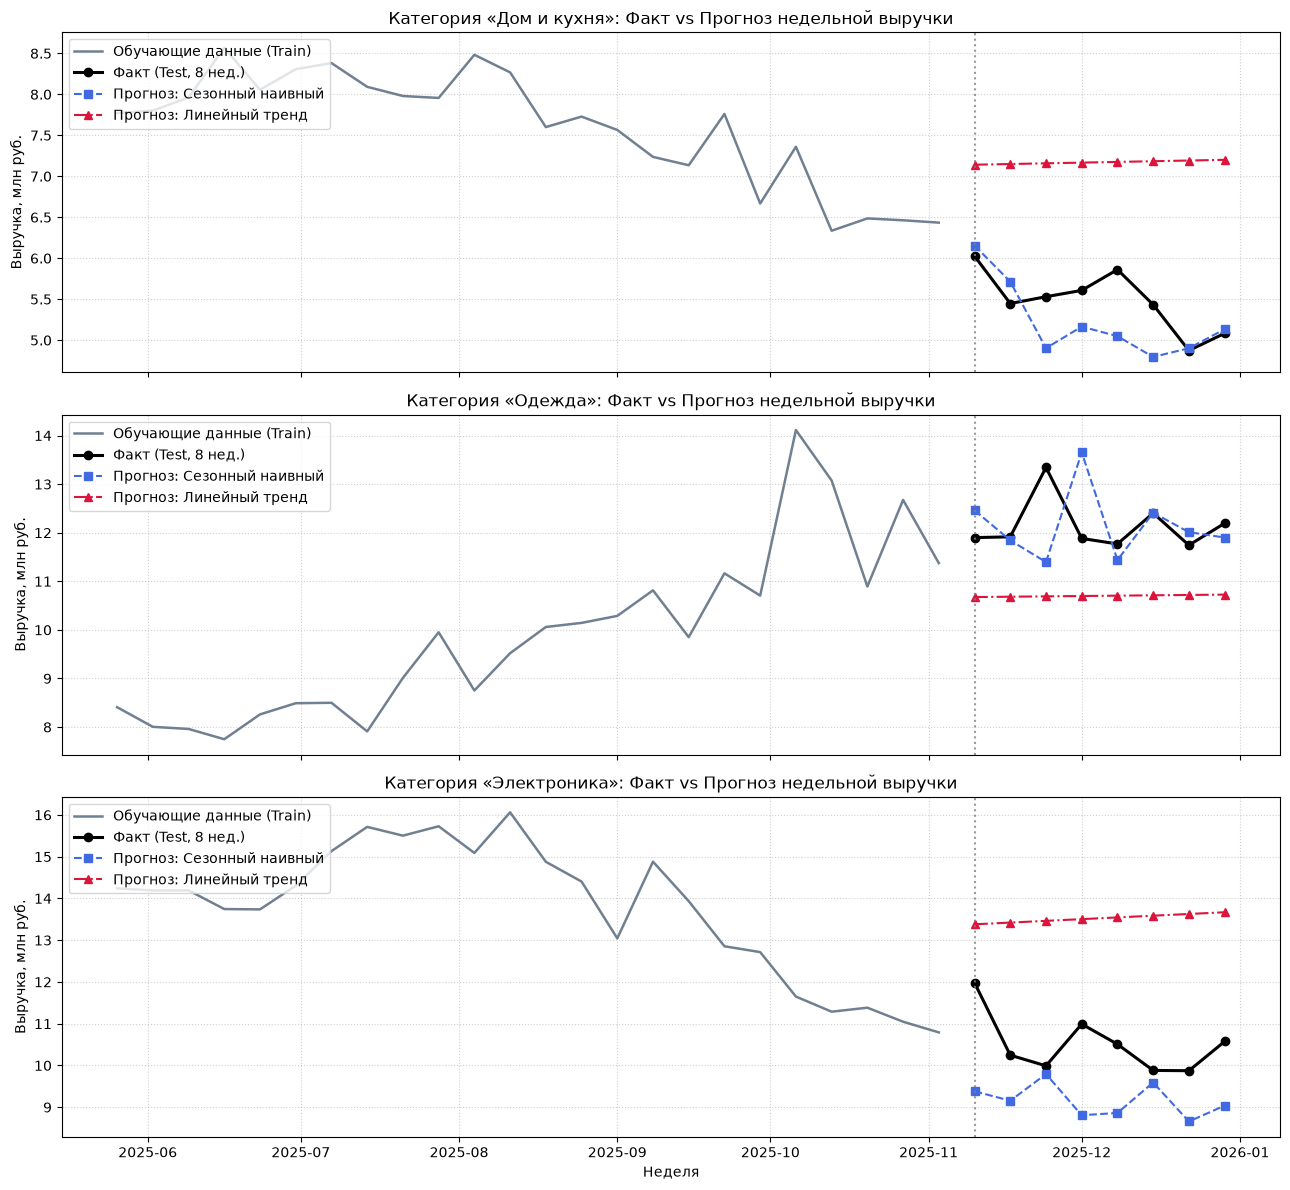

In [4]:
categories = list(weekly.columns)
fig, axes = plt.subplots(len(categories), 1, figsize=(13, 4 * len(categories)), sharex=True)

for ax, cat in zip(axes, categories):
    # Показываем последние 24 недели train для наглядности + 8 недель test
    ax.plot(train.index[-24:], train[cat].iloc[-24:] / 1e6, label="Обучающие данные (Train)", color="slategray", linewidth=1.8)
    ax.plot(test.index, test[cat] / 1e6, label="Факт (Test, 8 нед.)", color="black", marker="o", linewidth=2.2)
    ax.plot(test.index, results[cat]["seasonal"] / 1e6, label="Прогноз: Сезонный наивный", color="royalblue", linestyle="--", marker="s")
    ax.plot(test.index, results[cat]["trend"] / 1e6, label="Прогноз: Линейный тренд", color="crimson", linestyle="-.", marker="^")

    ax.axvline(test.index[0], color="gray", linestyle=":", alpha=0.8)
    ax.set_title(f"Категория «{cat}»: Факт vs Прогноз недельной выручки", fontsize=12)
    ax.set_ylabel("Выручка, млн руб.")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper left")

plt.xlabel("Неделя")
plt.tight_layout()
plt.show()
